# 03 – Analysis
Answers the business questions using `data/processed/access_clean.csv`.
Medians are used throughout because journey times are right-skewed.

## Q1. How does the access gap change from urban to remote rural areas?

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

df = pd.read_csv(Path("../data/processed/access_clean.csv"))
print(df.shape)

(6976, 25)


In [2]:
q1 = (df.groupby(["UrbanRural6fold2020", "UR_class"])
        .agg(zones=("Data_Zone", "count"),
             drive_GP=("drive_GP", "median"),
             PT_GP=("PT_GP", "median"),
             gap_GP=("gap_GP", "median"),
             ratio_GP=("ratio_GP", "median"),
             gap_post=("gap_post", "median"),
             gap_retail=("gap_retail", "median"))
        .round(1)
        .reset_index())
q1

,UrbanRural6fold2020,UR_class,zones,drive_GP,PT_GP,gap_GP,ratio_GP,gap_post,gap_retail
0,1,Large Urban Areas,2496,2.5,7.5,4.9,3.0,4.7,6.0
1,2,Other Urban Areas,2459,3.0,9.5,6.3,3.2,5.3,7.1
2,3,Accessible Small Towns,613,2.5,8.0,5.2,3.2,4.6,6.0
3,4,Remote Small Towns,202,2.7,8.7,5.6,3.1,4.6,4.7
4,5,Accessible Rural,805,5.8,15.4,9.3,2.8,6.7,11.6
5,6,Remote Rural,401,6.9,18.4,11.0,2.7,8.0,13.0


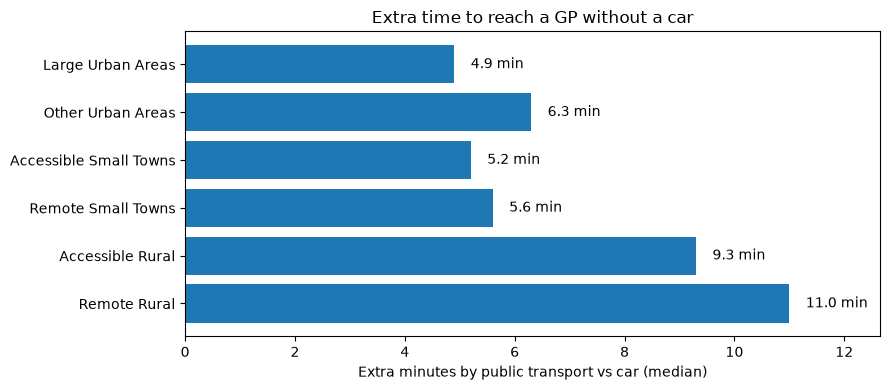

In [4]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(q1["UR_class"], q1["gap_GP"], color="#1f77b4")
ax.set_xlim(0, q1["gap_GP"].max() * 1.15)
ax.invert_yaxis()
ax.set_xlabel("Extra minutes by public transport vs car (median)")
ax.set_title("Extra time to reach a GP without a car")

for i, v in enumerate(q1["gap_GP"]):
    ax.text(v + 0.3, i, f"{v} min", va="center")

plt.tight_layout()
plt.savefig("../images/q1_gap_by_rurality.png", dpi=150)
plt.show()

**Finding:** the extra time without a car more than doubles from Large Urban Areas (4.9 min to a GP)
to Remote Rural areas (11.0 min), with a step change between small towns and rural areas rather than
a steady rise. The ratio moves the other way (3.0× urban vs 2.7× remote rural) because driving is also
slower in rural areas, so the rural disadvantage is mainly in absolute time: 18.4 min by public
transport vs 7.5 min in large urban areas. The same pattern holds for post offices and retail centres.